Here is my current progress of my neural network case study. I started by coding some of the main components of a single neuron, such as the activation function and loss function, before putting it together in an attempt to learn a single vector. 

I then moved onto making a PINN to solve Poisson's equation -u"(x) = 2, with BCs u(0)= 0 and u(1) = 0. After this, I started updating this model by implementing some better systems for parameter optimisation, such as Stochastic Gradient Descent (SGD). Since my models currently run with numerical differentiation or hard coded derivatives in the case of the Poisson's calculator, as of writing this my plan is to update this design by implementing automatic differentiation or backpropagation algorithms which I will then use to build upto more complicated PDEs such as the advection-diffusion equation. 

Then I might swap over to trying to design a PINN which will derive PDEs from data, as stated in (Chapter 4: Data-driven discovery of partial differential equations) of [Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations M. Raissi, P. Perdikaris, G.E. Karniadakis], but this is a problem for future Aleks.

In [2]:
import numpy as np
import math

def sigmoid(x):

    return (1 / (1 + np.exp(-x)))

tests = [-100, -10, -2, 0, 2, 10, 100]

for num in tests:

    print(sigmoid(num))

3.7200759760208356e-44
4.5397868702434395e-05
0.11920292202211755
0.5
0.8807970779778823
0.9999546021312976
1.0


In [3]:
y_true = [0,1,1,0]
y_pred = [0.1, 0.8, 0.7, 0.2]
y_pred = [0.01, 0.99, 0.9, 0.05]

tot = len(y_true)

def cross_entropy(truths, predicts):

    total_loss = []

    for i in range(len(truths)):

        true = truths[i]
        pred = predicts[i]

        L_comp = true * np.log(pred) + (1 - true) * np.log(1 - pred)

        total_loss.append(L_comp)
    
    cross_ent_loss = (-1 / len(truths)) * np.sum(total_loss)

    return cross_ent_loss

cross_entropy(y_true, y_pred)
     

np.float64(0.04418862043809495)

Here is a very simple model of me coding a single neuron to learn one vector. It looks very simple, though without this I might have struggled to give coherent answer to my friend who asked me "what does it actually mean when a NN learns something mathematically?". The act of learning is simply the parameters of the network being adapted iteratively in order to reduce the loss (error) between the training data (in this case y) and our output data (a).

In [ ]:
x = np.array([-4, -3, -2, -1, 1, 2, 3, 4])
y = np.array([ 0,  0,  0,  0, 1, 1, 1, 1])

#w = np.identity(8)
#b = np.array([0, 0, 0, 0, 0, 0, 0, 0])

w = 0.1
b = 0.0

learning_rate = 0.1

loss_from_w = lambda w: cross_entropy(y, sigmoid(w * x + b))
loss_from_b = lambda b: cross_entropy(y, sigmoid(w * x + b))


def numerical_derivative(func, x, h = 1e-5):

    if not callable(func):

        raise TypeError("func must be a callable function.")
    
    if not isinstance(x, (int, float)):

        raise TypeError("x must be a number.")
    
    if not isinstance(h, (int, float)) or h <= 0:

        
        raise ValueError("h must be a positive number.")

    try:
        return (func(x + h) - func(x - h)) / (2 * h)
    except Exception as e:
        raise RuntimeError(f"Error computing derivative: {e}")

for epoch in range(10000):

    z = w * x + b

    a = sigmoid(z)

    loss = cross_entropy(y,a)

    dloss_dw = numerical_derivative(loss_from_w, w)

    dloss_db = numerical_derivative(loss_from_b, b)

    w = w - learning_rate * dloss_dw

    b = b - learning_rate * dloss_db

    print(loss)


0.5774765065809107
0.47425239153790877
0.40329617798004463
0.352389079202407
0.3143389928767742
0.28487734647439245
0.26138544507642636
0.24219297290999242
0.22619359464488886
0.2126290319643584
0.2009635897881427
0.19080862792474892
0.18187554453133384
0.17394558939714716
0.16684993163219497
0.16045616131649776
0.15465893771934192
0.14937337589522276
0.14453028222985165
0.14007266382083378
0.1359531317402507
0.13213194216590193
0.12857549973931326
0.1252552006267517
0.12214652850050756
0.11922834109616418
0.11648230196995871
0.11389242402751334
0.1114446999182428
0.10912680054276383
0.10692782741621461
0.10483810794612539
0.1028490251586627
0.10095287526551656
0.09914274787890276
0.09741242476142081
0.09575629383258702
0.0941692758025488
0.09264676130922488
0.09118455683634323
0.08977883800576741
0.08842610909004098
0.08712316779411218
0.08586707451818784
0.08465512544601303
0.08348482891104231
0.08235388458072623
0.08126016507205142
0.08020169967070251
0.0791766598769007
0.0781833465

Here I further the toy model by extending w and b into appropriate matrices and vectors. I have left in my first idea on how to produce a numerical derivative for your amusement, I found the other one on the internet and was quick to adopt it.

In [5]:
x = np.array([-4, -3, -2, -1, 1, 2, 3, 4])
y = np.array([ 0,  0,  0,  0, 1, 1, 1, 1])

w = np.identity(8)
b = np.array([0, 0, 0, 0, 0, 0, 0, 0])


learning_rate = 0.1

loss_from_w = lambda w: cross_entropy(y, sigmoid(w @ x + b))
loss_from_b = lambda b: cross_entropy(y, sigmoid(w @ x + b))

"""
def numerical_derivative(func, x, h = 1e-5):

    is_matrix = all(isinstance(row, list) for row in func)

    if is_matrix:
         
        func = func @ func.conj().T

        if np.linalg.matrix_rank(func) == np.size(func):

            U, D, U_h = np.linalg.svd(func, full_matrices = True)

        else:
             
            U, D, U_h = np.linalg.svd(func, full_matrices = True)

            for i in range(np.size(func)):

                if D[i][i] == 0:

                    D[i][i] = 1

        print(U, D, U_h)

        grad_funct = np.array([])

        for i in range(np.size(func)):

            D_pert_plus = D[i][i] + h
            D_pert_minus = D[i][i] - h

            func_pert_plus = U @ D_pert_plus @ U_h
            func_pert_minus = U @ D_pert_minus @ U_h

            activation_plus = sigmoid(func_pert_plus @ x + b)
            activation_minus = sigmoid(func_pert_minus @ x + b)

            function_plus = cross_entropy(activation_plus)
            function_minus = cross_entropy(activation_minus)

            grad = (function_plus - function_minus) / (2 * h)

            grad_funct.append(grad)

            return grad"""

def numerical_gradient(func, parameters, h=1e-5):

    gradient = np.zeros_like(parameters, dtype=float)

    for index in np.ndindex(parameters.shape): ############################################################## what a good idea

        parameters_plus = parameters.copy()
        parameters_minus = parameters.copy()

        parameters_plus[index] += h
        parameters_minus[index] -= h

        loss_plus = func(parameters_plus)
        loss_minus = func(parameters_minus)

        gradient[index] = (loss_plus - loss_minus) / (2*h)

    return gradient

for epoch in range(100):

    z = w @ x + b

    a = sigmoid(z)

    loss = cross_entropy(y,a)

    dloss_dw = numerical_gradient(loss_from_w, w)
    dloss_db = numerical_gradient(loss_from_b, b)

    w = w - learning_rate * dloss_dw

    b = b - learning_rate * dloss_db

    print(loss, a)


0.12673174451318678 [0.01798621 0.04742587 0.11920292 0.26894142 0.73105858 0.88079708
 0.95257413 0.98201379]
0.11110165333213848 [0.01774949 0.04584459 0.11013115 0.23117186 0.76882814 0.88986885
 0.95415541 0.98225051]
0.09890173019261408 [0.01751506 0.04433954 0.10216683 0.20133448 0.79866552 0.89783317
 0.95566046 0.98248494]
0.0892854459598704 [0.01728672 0.0429288  0.09523916 0.17777547 0.82222453 0.90476084
 0.9570712  0.98271328]
0.08151112833566529 [0.01706422 0.04160387 0.08916288 0.15881843 0.84118157 0.91083712
 0.95839613 0.98293578]
0.07509160067615647 [0.01684734 0.04035721 0.08379353 0.1433003  0.8566997  0.91620647
 0.95964279 0.98315266]
0.06969597016411358 [0.01663588 0.03918216 0.079017   0.13040172 0.86959828 0.920983
 0.96081784 0.98336412]
0.06509255422586907 [0.01642964 0.03807276 0.0747421  0.11953481 0.88046519 0.9252579
 0.96192724 0.98357036]
0.061114677865048914 [0.01622841 0.03702371 0.07089513 0.11026981 0.88973019 0.92910487
 0.96297629 0.98377159]
0.05

Below is my first real attempt in making a PINN from scratch, to solve Poisson's equation with constant source functions and homogeneous Dirichlet BCs. I opted for tanh() rather than sigmoid() because that is what most other PINNs use from what I have heard. For the purposes of my training I gave it the actual second derivative of itself rather than the numerical approximation, which I will append to backpropagation later anyway. This model uses no computing tricks to increase efficiency, calculating each loss and updating the parameters (v, w, b and c) once per epoch. At the end there are some plots, one of the final output solution of the NN compared with the analytical solution and one the error convergence per epoch. 

[32 94 99 23  7 86  9 81 78 28 45 21 11 85 75  6 53 15 48 40 19 59 56 31
 39 34 38 88 57 27 84 82 16 55 72 52 91 18 66 89 30 58 98 65 73 49  0 69
 36 37 79 60 67 95 77 76 71 29 70 87 50 44 63 62  4 26 41 51  5 54 68 10
 25 33 35 80  8 43 20 12 93 64 17 96 61 97 90 24 42  3 83  1 22 13  2 47
 74 46 14 92]
-0.3440654199977318
-0.7904505100844451
PDE loss: 6.34006383029526
BC loss: 1.2412552150069072
Total loss: 8.822574260309075
Epoch 0: Loss = 8.104693216401524
Epoch 20: Loss = 2.5150258137212385
Epoch 40: Loss = 1.3848784050528322
Epoch 60: Loss = 0.9374797508046742
Epoch 80: Loss = 0.7138777499460479
Epoch 100: Loss = 0.5855408111665676
Epoch 120: Loss = 0.5024513006848362
Epoch 140: Loss = 0.4431865424274899
Epoch 160: Loss = 0.3979081011776938
Epoch 180: Loss = 0.3617087159220014
Epoch 200: Loss = 0.33188446441152697
Epoch 220: Loss = 0.3067832944521058
Epoch 240: Loss = 0.2853028683544089
Epoch 260: Loss = 0.26665986059693897
Epoch 280: Loss = 0.2502751064704311
Epoch 300: Loss = 0

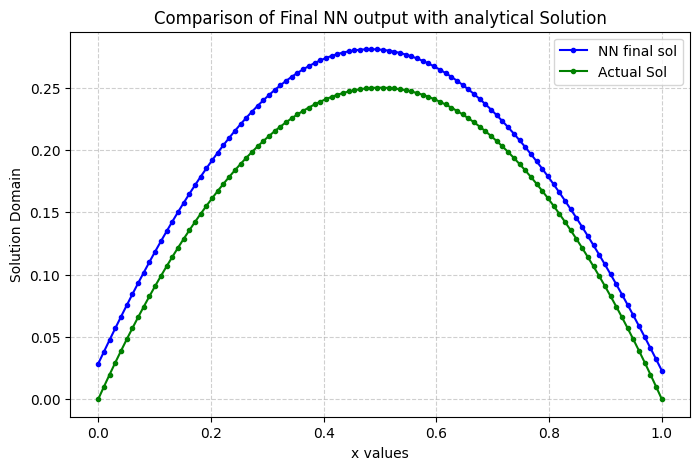

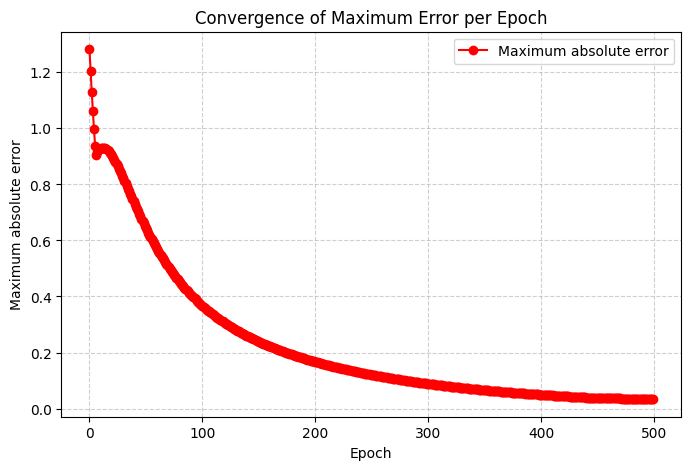

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def actual_solution(x): ## TO be used for comparison in plots

    sol = x * (1 - x)

    return sol

def neural_network(x, w, b, v ,c):

    Neu_net = []

    for i in range(0,10):

        Neu_net.append(v[i] * np.tanh(w[i] * x + b[i]))

    u = np.sum(Neu_net) + c

    return u

def u_dderiv(x, w, b, v):
        
    Neu_net = []

    for i in range(0,10):

        Neu_net.append(v[i] * w[i]**2 * -2 * 1/((np.cosh(w[i] * x + b[i]))**2) * np.tanh(w[i] * x + b[i]))

    u_pp = np.sum(Neu_net)

    return u_pp

def u_dderiv_approx(x, w, b, v ,c):

    h = 1e-3

    u_h_forward = neural_network(x + h, w, b, v ,c)
    u_h_backward = neural_network(x - h, w, b, v, c)
    u = neural_network(x, w, b, v, c)

    u_pp_h = 1/h**2 * (u_h_forward - 2 * u + u_h_backward)

    return u_pp_h

def PDE_loss(x_points, w, b, v):

    residuals = []

    for x in x_points:

        residual = u_dderiv(x, w, b, v) + 2

        residuals.append(residual)

    loss = np.mean(np.array(residuals)**2)

    return loss

def BC_loss(w, b, v, c):

    u_left = neural_network(0, w, b, v, c)

    u_right = neural_network(1, w, b, v, c)

    loss = 0.5 * (u_left**2 + u_right**2)

    return loss

def total_loss(x_points, w, b, v, c, constant_BC=2):

    loss_PDE = PDE_loss(x_points, w, b, v)
    loss_BC = BC_loss(w, b, v, c)

    loss = loss_PDE + constant_BC * loss_BC

    return loss

def mini_batch_SGD(x): ### Just a test to see how to permute the arrays

    total_batch = len(x)

    batch_size = total_batch / 10

    randomised = np.random.permutation(total_batch)

    pr = print(randomised)

    return pr

x_points = np.linspace(0,1,100)
mini_batch_SGD(x_points)


def numerical_gradient(func, parameters, h=1e-5):

    parameters = np.asarray(parameters, dtype=float)

    gradient = np.zeros_like(parameters)

    for index in np.ndindex(parameters.shape):

        parameters_plus = parameters.copy()
        parameters_minus = parameters.copy()

        parameters_plus[index] += h
        parameters_minus[index] -= h

        loss_plus = func(parameters_plus)
        loss_minus = func(parameters_minus)

        gradient[index] = (loss_plus - loss_minus)/(2*h)

    return gradient
    
x_points = np.linspace(0,1,100)

w = np.random.randn(10)
b = np.random.randn(10)
v = np.random.randn(10)
c = 0.0

nn_predictions = np.array([neural_network(x, w, b, v, c) for x in x_points])

#print(neural_network(0.5, w, b, v, c))
#print(neural_network(0.7, w, b, v, c))
print("PDE loss:", PDE_loss(x_points, w, b, v))
print("BC loss:", BC_loss(w, b, v, c))
print("Total loss:", total_loss(x_points, w, b, v, c))

learning_rate = 0.002
epochs = 500

epoch_errors = []

for epoch in range(epochs):

    grad_w = numerical_gradient(lambda W: total_loss(x_points, W, b, v, c), w)

    grad_b = numerical_gradient(lambda B: total_loss(x_points, w, B, v, c), b)

    grad_v = numerical_gradient(lambda V: total_loss(x_points, w, b, V, c), v)

    grad_c = numerical_gradient(lambda C: total_loss(x_points, w, b, v, C), np.array(c))

    w -= learning_rate * grad_w
    b -= learning_rate * grad_b
    v -= learning_rate * grad_v
    c -= learning_rate * grad_c.item()

    nn_prediction_epoch = np.array([neural_network(x, w, b, v, c) for x in x_points])
    
    real_sols = np.array([actual_solution(x) for x in x_points])

    errors = np.abs(nn_prediction_epoch - real_sols)

    max_error = np.max(errors)

    epoch_errors.append(max_error)

    if epoch % 20 == 0:

        loss = total_loss(x_points, w, b, v, c)

        print(f"Epoch {epoch}: Loss = {loss}")

    if epoch == range(epochs)[-1]:

        plt.figure(figsize=(8, 5))

        plt.plot(x_points, nn_prediction_epoch, marker='.', color='blue', label='NN final sol')

        plt.plot(x_points, actual_solution(x_points), marker='.', color='green', label='Actual Sol')

        plt.xlabel('x values')
        plt.ylabel('Solution Domain')
        plt.title('Comparison of Final NN output with analytical Solution')

        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.6)

        plt.show()

plt.figure(figsize=(8, 5))

plt.plot(range(epochs), epoch_errors,
         marker='o', color='red', label='Maximum absolute error')

plt.xlabel('Epoch number')
plt.ylabel('Maximum absolute error')
plt.title('Convergence of Maximum Error per Epoch')

plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()


In [70]:
def mini_batch_SGD(x):

    total_batch = len(x)

    batch_size = total_batch // 10

    randomised = np.random.permutation(x)

    for i in range(0, total_batch, batch_size):

        new_arrays = randomised[i : i + batch_size]

        print(new_arrays)

    return 

x_points = np.linspace(0,1,101)
mini_batch_SGD(x_points)


[0.59 0.69 0.01 0.28 0.51 0.73 0.83 0.02 0.36 0.7 ]
[0.09 0.84 0.18 0.68 0.19 0.07 0.99 0.77 0.98 1.  ]
[0.08 0.9  0.4  0.25 0.95 0.06 0.79 0.35 0.49 0.16]
[0.41 0.65 0.5  0.42 0.55 0.38 0.56 0.71 0.86 0.53]
[0.45 0.62 0.15 0.17 0.91 0.03 0.72 0.75 0.34 0.82]
[0.32 0.78 0.37 0.47 0.57 0.2  0.52 0.27 0.21 0.3 ]
[0.74 0.88 0.67 0.31 0.1  0.48 0.12 0.33 0.58 0.13]
[0.93 0.43 0.61 0.85 0.22 0.63 0.81 0.29 0.23 0.87]
[0.   0.05 0.04 0.64 0.94 0.66 0.46 0.89 0.96 0.54]
[0.97 0.24 0.92 0.39 0.8  0.11 0.76 0.26 0.44 0.6 ]
[0.14]


At present same as above only with the use of mini-batch SGD for faster computing and more iterations to help converge to optimal parameters per epoch.

Epoch 0: Loss = 5.555031400413128
Epoch 20: Loss = 0.8972607410541403
Epoch 40: Loss = 0.5058910296378962
Epoch 60: Loss = 0.27436315315925264
Epoch 80: Loss = 0.38195815442934494
Epoch 100: Loss = 0.30224765883298704
Epoch 120: Loss = 0.4239896842224456
Epoch 140: Loss = 0.38927008704280075
Epoch 160: Loss = 0.35207533596930374
Epoch 180: Loss = 0.2033758498237391
Epoch 200: Loss = 0.19420350491682223
Epoch 220: Loss = 0.12328583861925314
Epoch 240: Loss = 0.25906469911791546
Epoch 260: Loss = 0.24994833571658562
Epoch 280: Loss = 0.14486552764392996
Epoch 300: Loss = 0.1406247205078124
Epoch 320: Loss = 0.1101437178577013
Epoch 340: Loss = 0.028891603093098885
Epoch 360: Loss = 0.06542018123478814
Epoch 380: Loss = 0.06007136267174215
Epoch 400: Loss = 0.014084840578096003
Epoch 420: Loss = 0.02484987189732588
Epoch 440: Loss = 0.006142061653672658
Epoch 460: Loss = 0.009413811580709327
Epoch 480: Loss = 0.021385124358250577


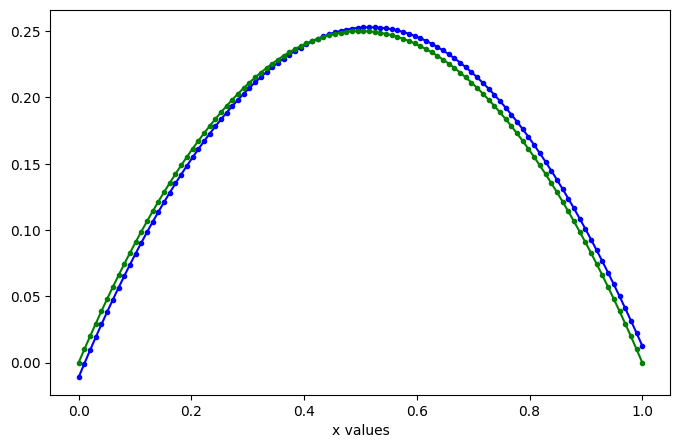

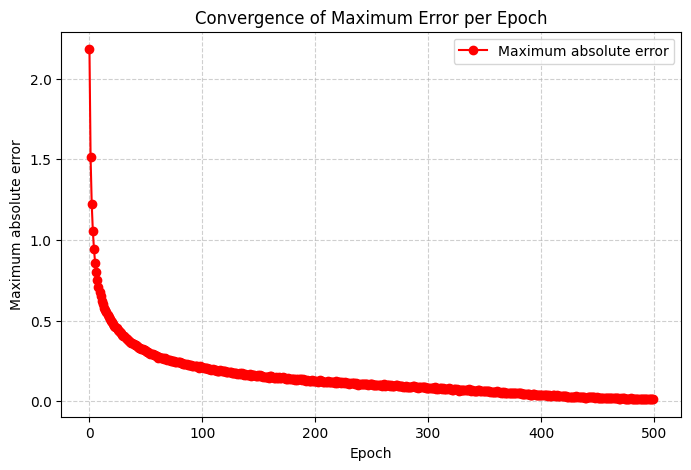

In [ ]:
epoch_errors = []


w = np.random.randn(10)
b = np.random.randn(10)
v = np.random.randn(10)
c = 0.0

for epoch in range(epochs):

    total_batch = len(x_points)

    #print(total_batch)
    
    batch_size = int(total_batch / 10)

    #print(batch_size)

    randomised = np.random.permutation(x_points)

    #print(randomised)

    for i in range(0, total_batch, batch_size):

        new_arrays = randomised[i : i + batch_size]

        grad_w = numerical_gradient(lambda W: total_loss(new_arrays, W, b, v, c), w)

        grad_b = numerical_gradient(lambda B: total_loss(new_arrays, w, B, v, c), b)

        grad_v = numerical_gradient(lambda V: total_loss(new_arrays, w, b, V, c), v)

        grad_c = numerical_gradient(lambda C: total_loss(new_arrays, w, b, v, C), np.array(c))

        w -= learning_rate * grad_w
        b -= learning_rate * grad_b
        v -= learning_rate * grad_v
        c -= learning_rate * grad_c.item()

    nn_prediction_epoch = np.array([neural_network(x, w, b, v, c) for x in x_points])
    
    real_sols = np.array([actual_solution(x) for x in x_points])

    errors = np.abs(nn_prediction_epoch - real_sols)

    max_error = np.max(errors)

    epoch_errors.append(max_error)

    if epoch % 20 == 0:

        loss = total_loss(new_arrays, w, b, v, c)

        print(f"Epoch {epoch}: Loss = {loss}")

    """if epoch == range(epochs)[-1]:

        plt.figure(figsize=(8, 5))

        plt.plot(new_arrays, nn_prediction_epoch, marker='.', color='blue', label='NN final sol')

        plt.plot(new_arrays, actual_solution(new_arrays), marker='.', color='green', label='Actual Sol')

        plt.xlabel('x values')
        plt.ylabel('Solution Domain')
        plt.title('Comparison of Final NN output with analytical Solution')

        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.6)

        plt.show()"""


x_plot = np.linspace(0, 1, 100)

nn_prediction_final = np.array([
    neural_network(x, w, b, v, c) for x in x_plot])

real_sols = np.array([
    actual_solution(x) for x in x_plot])

plt.figure(figsize=(8, 5))

plt.plot(x_plot, nn_prediction_final, marker='.', color='blue', label='NN final sol')

plt.plot(x_plot, real_sols, marker='.', color='green', label='Actual Sol')

plt.xlabel('x values')






plt.figure(figsize=(8, 5))

plt.plot(range(epochs), epoch_errors, marker='o', color='red', label='Maximum absolute error')

plt.xlabel('Epoch number')
plt.ylabel('Maximum absolute error')
plt.title('Convergence of Maximum Error per Epoch')

plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()